<a href="https://colab.research.google.com/github/vaibhavkadwe/ExploratoryAnalysis-of-House-Prices/blob/main/AI_MLmidterm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# INTRODUCTION


Dataset: House Prices: Advanced Regression Techniques (Kaggle), file train.csv , about
1,460 rows and 81 columns.
Tools: Python, Pandas, NumPy, Matplotlib, Seaborn, SciPy, Jupyter Notebook.
Objective: Use exploratory data analysis only (no machine learning) to understand which
factors drive house sale prices, and to practise the full EDA workflow.

In [2]:
from google.colab import files
uploaded = files.upload()

Saving train.csv to train.csv


# DATA LOADING

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

plt.rcParams["figure.figsize"] = (8, 5)
sns.set_style("whitegrid")

df = pd.read_csv("train.csv")

print("Shape:", df.shape)
display(df.head())
df.info()

missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing_pct = (missing / len(df)) * 100
print("\nMissing columns:")
print(pd.DataFrame({"missing_count": missing, "missing_pct": missing_pct.round(2)}))

Shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

# DATA UNDERSTANDING

In [4]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df.select_dtypes(include=["object"]).columns.tolist()

ordinal_map = {
    "ExterQual": ["Po", "Fa", "TA", "Gd", "Ex"],
    "KitchenQual": ["Po", "Fa", "TA", "Gd", "Ex"],
}

for col, order in ordinal_map.items():
    if col in df.columns:
        df[col] = pd.Categorical(df[col], categories=order, ordered=True)

# Note: OverallQual is numeric in storage (1-10) but ordinal in meaning.
summary_rows = []
for col in df.columns:
    col_type = (
        "ordinal" if col in ordinal_map or col == "OverallQual"
        else ("numerical" if col in numeric_cols else "categorical")
    )
    examples = df[col].dropna().unique()[:3].tolist()
    summary_rows.append({
        "column_name": col,
        "type": col_type,
        "unique_values": df[col].nunique(dropna=True),
        "examples": examples
    })

var_summary = pd.DataFrame(summary_rows)
display(var_summary)

,column_name,type,unique_values,examples
0,Id,numerical,1460,"[1, 2, 3]"
1,MSSubClass,numerical,15,"[60, 20, 70]"
2,MSZoning,categorical,5,"[RL, RM, C (all)]"
3,LotFrontage,numerical,110,"[65.0, 80.0, 68.0]"
4,LotArea,numerical,1073,"[8450, 9600, 11250]"
...,...,...,...,...
76,MoSold,numerical,12,"[2, 5, 9]"
77,YrSold,numerical,5,"[2008, 2007, 2006]"
78,SaleType,categorical,9,"[WD, New, COD]"
79,SaleCondition,categorical,6,"[Normal, Abnorml, Partial]"


# Univariate analysis

In [5]:
display(df[numeric_cols].describe())

for col in ["SalePrice", "GrLivArea", "LotArea"]:
    s = df[col].dropna()
    mean_val = s.mean()
    median_val = s.median()
    mode_val = s.mode().iloc[0]
    std_val = s.std()
    var_val = s.var()
    rng_val = s.max() - s.min()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr_val = q3 - q1
    skew_val = stats.skew(s)
    kurt_val = stats.kurtosis(s)

    skew_note = "right skewed" if mean_val > median_val else ("left skewed" if mean_val < median_val else "roughly symmetric")
    print(f"\n--- {col} ({skew_note}) ---")
    print(f"Mean: {mean_val:.2f} | Median: {median_val:.2f} | Mode: {mode_val}")
    print(f"Std: {std_val:.2f} | Var: {var_val:.2f} | Range: {rng_val} | IQR: {iqr_val:.2f}")
    print(f"Skewness: {skew_val:.2f} | Kurtosis: {kurt_val:.2f}")

for col in ["Neighborhood", "HouseStyle"]:
    print(f"\n--- {col} ---")
    print("Mode:", df[col].mode().iloc[0])
    print(df[col].value_counts())

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000



--- SalePrice (right skewed) ---
Mean: 180921.20 | Median: 163000.00 | Mode: 140000
Std: 79442.50 | Var: 6311111264.30 | Range: 720100 | IQR: 84025.00
Skewness: 1.88 | Kurtosis: 6.51

--- GrLivArea (right skewed) ---
Mean: 1515.46 | Median: 1464.00 | Mode: 864
Std: 525.48 | Var: 276129.63 | Range: 5308 | IQR: 647.25
Skewness: 1.37 | Kurtosis: 4.87

--- LotArea (right skewed) ---
Mean: 10516.83 | Median: 9478.50 | Mode: 7200
Std: 9981.26 | Var: 99625649.65 | Range: 213945 | IQR: 4048.00
Skewness: 12.20 | Kurtosis: 202.54

--- Neighborhood ---
Mode: NAmes
Neighborhood
NAmes      225
CollgCr    150
OldTown    113
Edwards    100
Somerst     86
Gilbert     79
NridgHt     77
Sawyer      74
NWAmes      73
SawyerW     59
BrkSide     58
Crawfor     51
Mitchel     49
NoRidge     41
Timber      38
IDOTRR      37
ClearCr     28
SWISU       25
StoneBr     25
Blmngtn     17
MeadowV     17
BrDale      16
Veenker     11
NPkVill      9
Blueste      2
Name: count, dtype: int64

--- HouseStyle ---
Mode:

# Bivariate & multivariate analysis

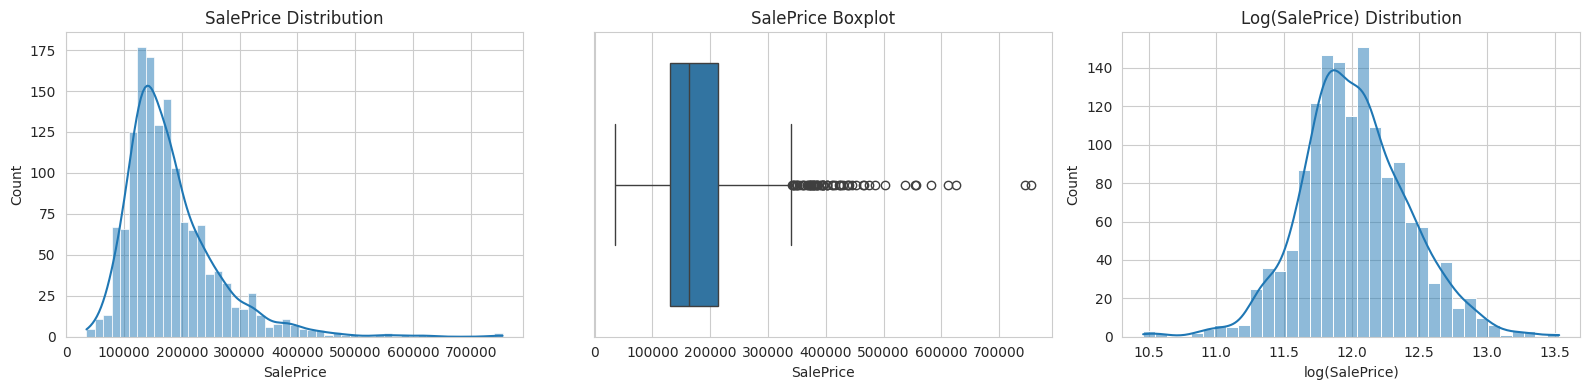

Skewness before log: 1.88
Skewness after log:  0.12


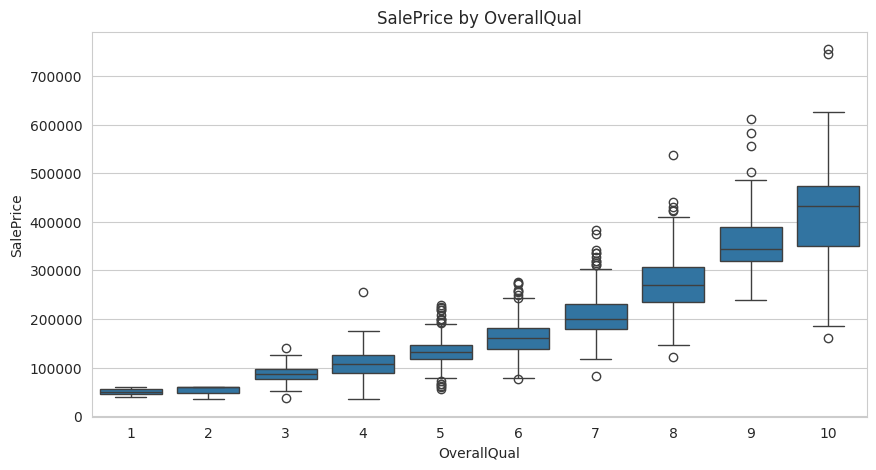

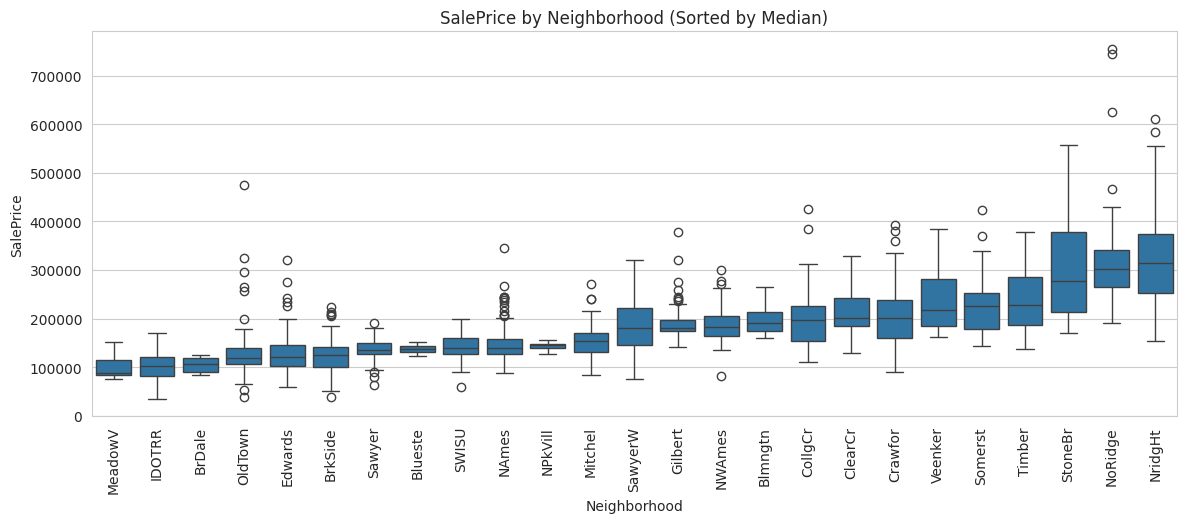

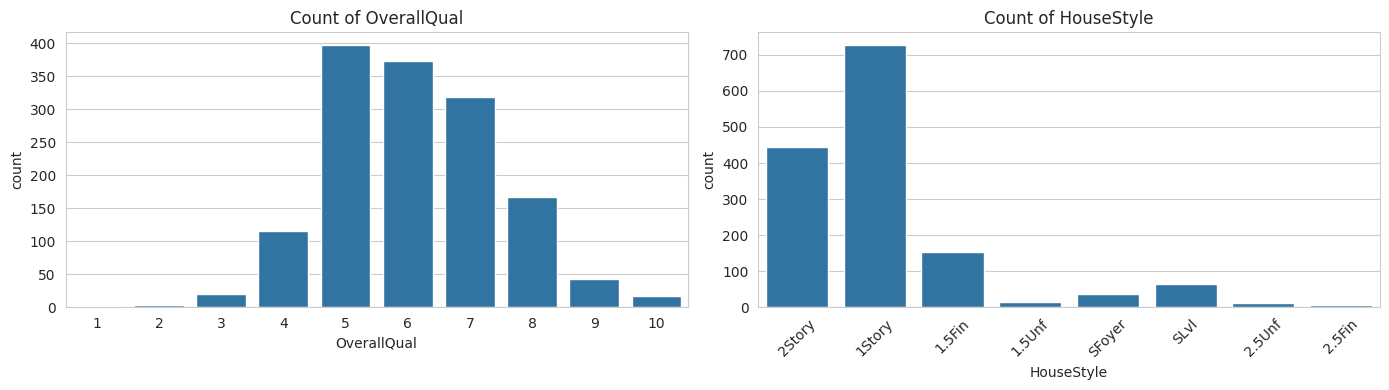

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(df["SalePrice"], kde=True, ax=axes[0])
axes[0].set_title("SalePrice Distribution")
axes[0].set_xlabel("SalePrice")
axes[0].set_ylabel("Count")

sns.boxplot(x=df["SalePrice"], ax=axes[1])
axes[1].set_title("SalePrice Boxplot")
axes[1].set_xlabel("SalePrice")

log_price = np.log(df["SalePrice"])
sns.histplot(log_price, kde=True, ax=axes[2])
axes[2].set_title("Log(SalePrice) Distribution")
axes[2].set_xlabel("log(SalePrice)")
axes[2].set_ylabel("Count")

plt.tight_layout()
plt.show()

print(f"Skewness before log: {stats.skew(df['SalePrice']):.2f}")
print(f"Skewness after log:  {stats.skew(log_price):.2f}")

plt.figure(figsize=(10, 5))
sns.boxplot(x="OverallQual", y="SalePrice", data=df)
plt.title("SalePrice by OverallQual")
plt.show()

order_neigh = df.groupby("Neighborhood")["SalePrice"].median().sort_values().index
plt.figure(figsize=(14, 5))
sns.boxplot(x="Neighborhood", y="SalePrice", data=df, order=order_neigh)
plt.title("SalePrice by Neighborhood (Sorted by Median)")
plt.xticks(rotation=90)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.countplot(x="OverallQual", data=df, ax=axes[0])
axes[0].set_title("Count of OverallQual")

sns.countplot(x="HouseStyle", data=df, ax=axes[1])
axes[1].set_title("Count of HouseStyle")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

In [7]:
num_df = df[numeric_cols]
cov_matrix = num_df.cov()
corr_matrix = num_df.corr(method="pearson")

top_corr = corr_matrix["SalePrice"].drop("SalePrice").reindex(
    corr_matrix["SalePrice"].drop("SalePrice").abs().sort_values(ascending=False).index
)
print("Top 10 features correlated with SalePrice:")
print(top_corr.head(10))

print("\nTop 3 features - Covariance vs Pearson Correlation with SalePrice:")
for feat in top_corr.head(3).index:
    print(f"{feat}: cov = {cov_matrix.loc[feat, 'SalePrice']:.2f}, corr = {corr_matrix.loc[feat, 'SalePrice']:.4f}")

ord_cols = [c for c in ["OverallQual", "ExterQual", "KitchenQual"] if c in df.columns]
if ord_cols:
    ord_num = df[ord_cols].apply(lambda s: s.cat.codes if hasattr(s, "cat") else s)
    ord_num["SalePrice"] = df["SalePrice"]
    print("\nSpearman correlation with SalePrice (ordinal features):")
    print(ord_num.corr(method="spearman")["SalePrice"])

Top 10 features correlated with SalePrice:
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
Name: SalePrice, dtype: float64

Top 3 features - Covariance vs Pearson Correlation with SalePrice:
OverallQual: cov = 86904.13, corr = 0.7910
GrLivArea: cov = 29581866.74, corr = 0.7086
GarageCars: cov = 38020.18, corr = 0.6404

Spearman correlation with SalePrice (ordinal features):
OverallQual    0.809829
ExterQual      0.684014
KitchenQual    0.672849
SalePrice      1.000000
Name: SalePrice, dtype: float64


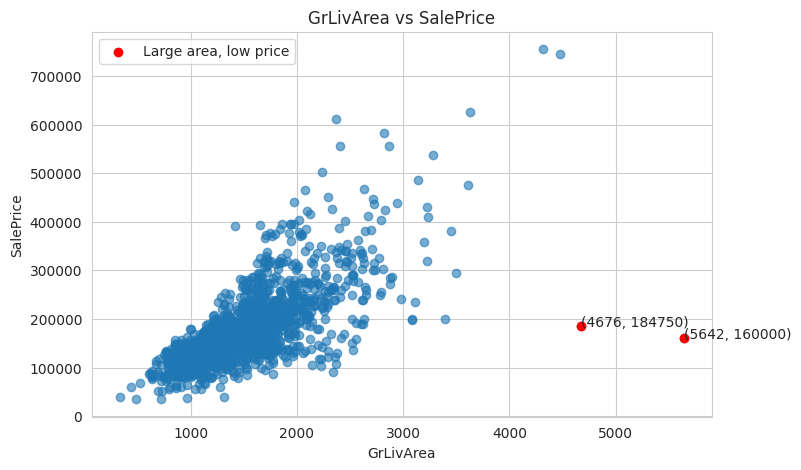

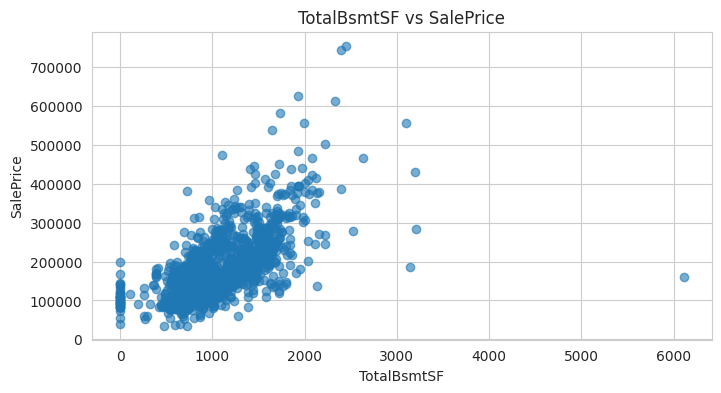

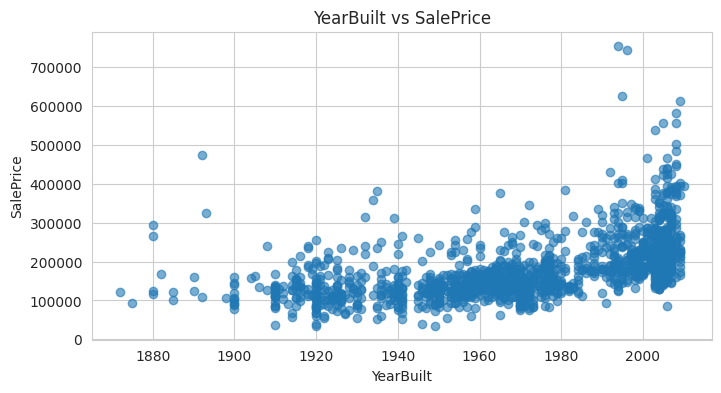

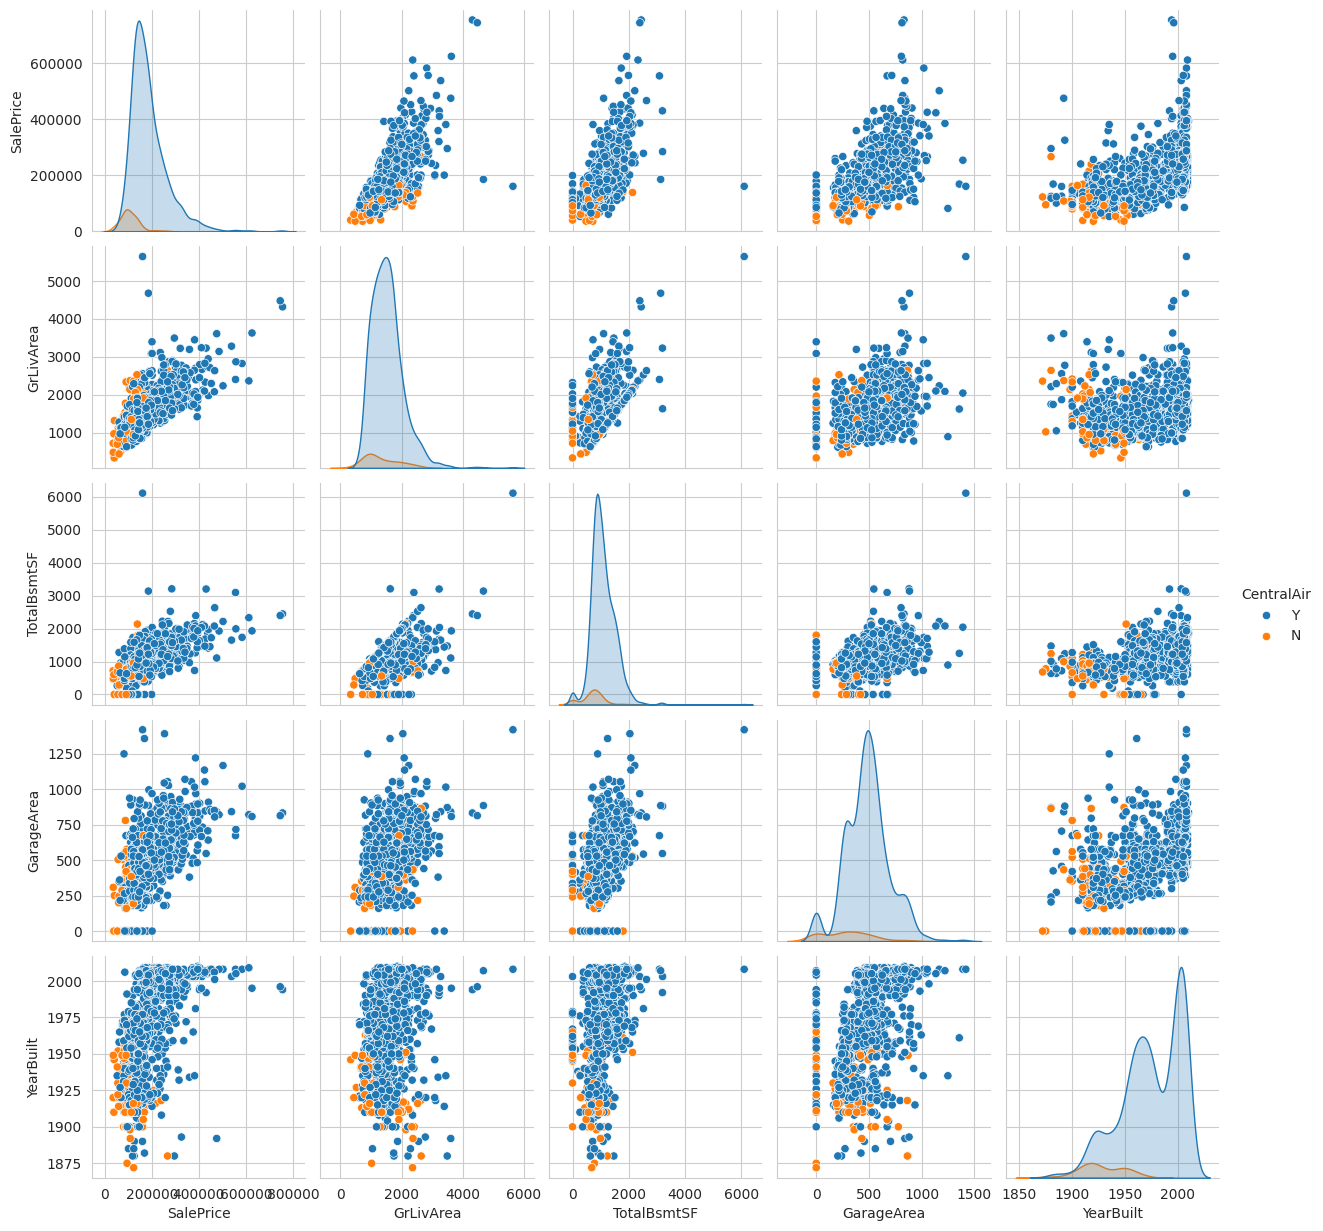

In [8]:
plt.figure(figsize=(8, 5))
plt.scatter(df["GrLivArea"], df["SalePrice"], alpha=0.6)
outliers_area = df[(df["GrLivArea"] > 4000) & (df["SalePrice"] < 300000)]
plt.scatter(outliers_area["GrLivArea"], outliers_area["SalePrice"], color="red", label="Large area, low price")
for _, row in outliers_area.iterrows():
    plt.annotate(f"({row['GrLivArea']}, {row['SalePrice']})", (row["GrLivArea"], row["SalePrice"]))
plt.title("GrLivArea vs SalePrice")
plt.xlabel("GrLivArea")
plt.ylabel("SalePrice")
plt.legend()
plt.show()

for col in ["TotalBsmtSF", "YearBuilt"]:
    plt.figure(figsize=(8, 4))
    plt.scatter(df[col], df["SalePrice"], alpha=0.6)
    plt.title(f"{col} vs SalePrice")
    plt.xlabel(col)
    plt.ylabel("SalePrice")
    plt.show()

selected = ["SalePrice", "GrLivArea", "TotalBsmtSF", "GarageArea", "YearBuilt"]
hue_col = "CentralAir" if "CentralAir" in df.columns else None
sns.pairplot(df[selected + ([hue_col] if hue_col else [])], diag_kind="kde", hue=hue_col)
plt.show()

# Outlier analysis

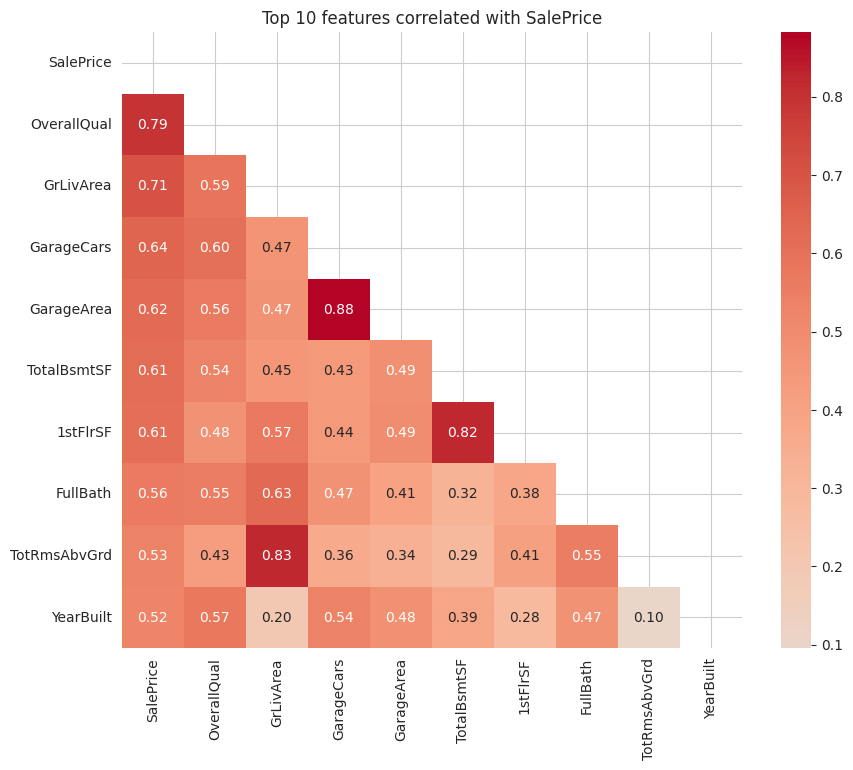

In [9]:
top10 = top_corr.head(10).index.tolist()
if "SalePrice" not in top10:
    top10 = ["SalePrice"] + top10[:9]

corr_top = df[top10].corr()
mask = np.triu(np.ones_like(corr_top, dtype=bool))

plt.figure(figsize=(10, 8))
sns.heatmap(corr_top, annot=True, fmt=".2f", cmap="coolwarm", center=0, mask=mask)
plt.title("Top 10 features correlated with SalePrice")
plt.show()

GrLivArea -> IQR count: 31, Z-score count: 16, Overlap: 16
SalePrice -> IQR count: 61, Z-score count: 22, Overlap: 22


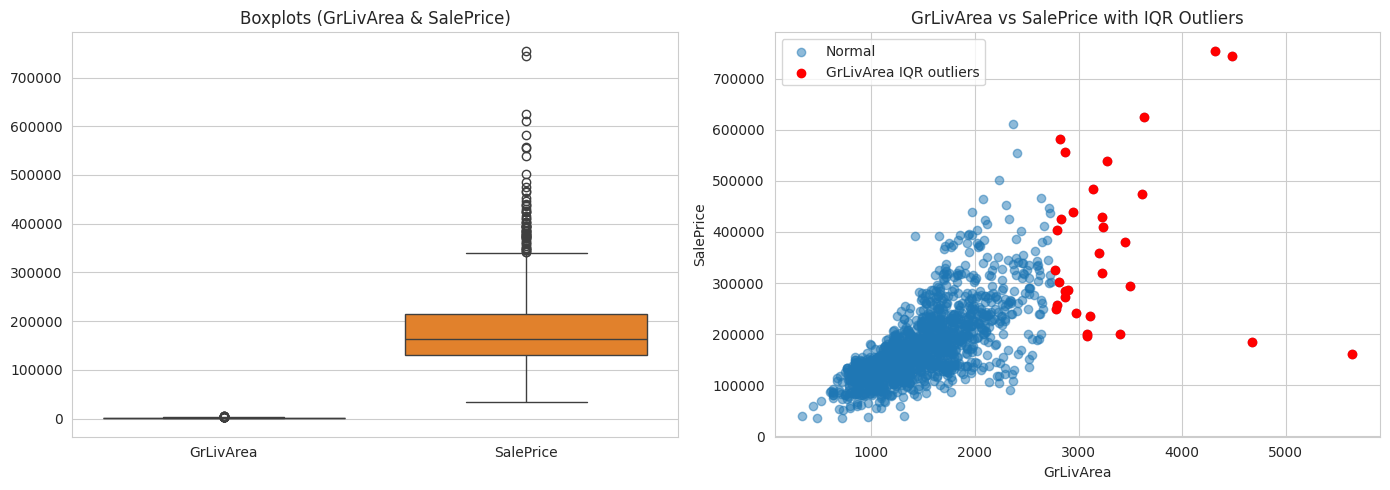

Original shape: (1460, 81) | Cleaned shape: (1458, 81)


In [10]:
def iqr_outliers(series):
    s = series.dropna()
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return df.loc[s.index[(s < lower) | (s > upper)]]

def zscore_outliers(series, threshold=3):
    s = series.dropna()
    z = (s - s.mean()) / s.std()
    return df.loc[s.index[z.abs() > threshold]]

for col in ["GrLivArea", "SalePrice"]:
    a = iqr_outliers(df[col])
    b = zscore_outliers(df[col])
    overlap = a.index.intersection(b.index)
    print(f"{col} -> IQR count: {len(a)}, Z-score count: {len(b)}, Overlap: {len(overlap)}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df[["GrLivArea", "SalePrice"]], ax=axes[0])
axes[0].set_title("Boxplots (GrLivArea & SalePrice)")

iqr_gl = iqr_outliers(df["GrLivArea"])
axes[1].scatter(df["GrLivArea"], df["SalePrice"], alpha=0.5, label="Normal")
axes[1].scatter(iqr_gl["GrLivArea"], iqr_gl["SalePrice"], color="red", label="GrLivArea IQR outliers")
axes[1].set_title("GrLivArea vs SalePrice with IQR Outliers")
axes[1].set_xlabel("GrLivArea")
axes[1].set_ylabel("SalePrice")
axes[1].legend()
plt.tight_layout()
plt.show()

# Example decision: remove extreme large-area/low-price outliers if desired
df_clean = df.drop(index=df[(df["GrLivArea"] > 4000) & (df["SalePrice"] < 300000)].index).copy()
print("Original shape:", df.shape, "| Cleaned shape:", df_clean.shape)

In [11]:
dup_count = df.duplicated().sum()
print("Duplicate rows:", dup_count)
if dup_count > 0:
    df = df.drop_duplicates()
    print("New shape after removing duplicates:", df.shape)

for col in categorical_cols:
    vals = df[col].dropna().astype(str)
    cleaned = vals.str.strip()
    if not vals.equals(cleaned):
        df[col] = df[col].where(df[col].isna(), cleaned)

none_cols = ["PoolQC", "Alley", "Fence", "FireplaceQu", "GarageType"]
for col in none_cols:
    if col in df.columns:
        if hasattr(df[col], "cat") and "None" not in df[col].cat.categories:
            df[col] = df[col].cat.add_categories("None")
        df[col] = df[col].fillna("None")

if "LotFrontage" in df.columns and "Neighborhood" in df.columns:
    df["LotFrontage"] = df["LotFrontage"].fillna(
        df.groupby("Neighborhood")["LotFrontage"].transform("median")
    )

for col in df.select_dtypes(include=[np.number]).columns:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].median())

for col in df.select_dtypes(include=["object", "category"]).columns:
    if df[col].isnull().sum() > 0:
        if hasattr(df[col], "cat") and "Missing" not in df[col].cat.categories:
            df[col] = df[col].cat.add_categories("Missing")
        df[col] = df[col].fillna("Missing")

print("Remaining total missing values:", df.isnull().sum().sum())

if "YearBuilt" in df.columns and "YrSold" in df.columns:
    print("Rows where YearBuilt > YrSold:", (df["YearBuilt"] > df["YrSold"]).sum())
for col in ["GrLivArea", "LotArea", "TotalBsmtSF", "GarageArea", "SalePrice"]:
    if col in df.columns:
        print(f"Negative values in {col}: {(df[col] < 0).sum()}")

Duplicate rows: 0
Remaining total missing values: 0
Rows where YearBuilt > YrSold: 0
Negative values in GrLivArea: 0
Negative values in LotArea: 0
Negative values in TotalBsmtSF: 0
Negative values in GarageArea: 0
Negative values in SalePrice: 0


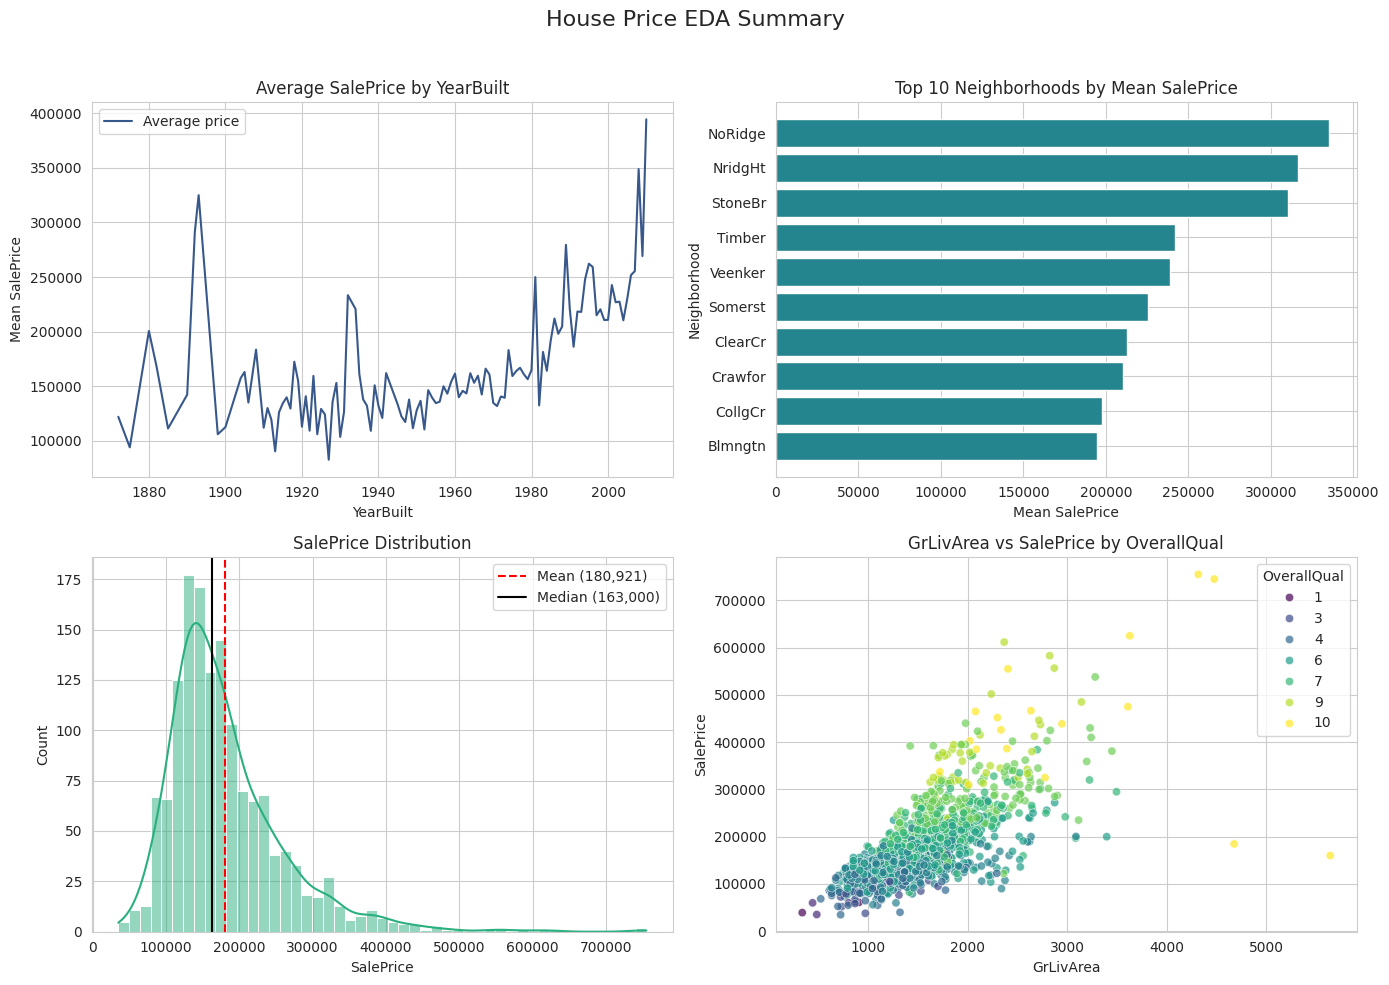

In [12]:
palette = sns.color_palette("viridis", 10)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Panel 1: Line plot of mean SalePrice by YearBuilt
yr_price = df.groupby("YearBuilt")["SalePrice"].mean()
axes[0, 0].plot(yr_price.index, yr_price.values, color=palette[2], label="Average price")
axes[0, 0].set_title("Average SalePrice by YearBuilt")
axes[0, 0].set_xlabel("YearBuilt")
axes[0, 0].set_ylabel("Mean SalePrice")
axes[0, 0].legend()

# Panel 2: Horizontal bar plot of top 10 Neighborhoods by mean SalePrice
top10_neigh = df.groupby("Neighborhood")["SalePrice"].mean().sort_values(ascending=False).head(10).sort_values()
axes[0, 1].barh(top10_neigh.index, top10_neigh.values, color=palette[4])
axes[0, 1].set_title("Top 10 Neighborhoods by Mean SalePrice")
axes[0, 1].set_xlabel("Mean SalePrice")
axes[0, 1].set_ylabel("Neighborhood")

# Panel 3: SalePrice histplot + KDE with mean & median lines
sns.histplot(df["SalePrice"], kde=True, color=palette[6], ax=axes[1, 0])
mean_sp = df["SalePrice"].mean()
med_sp = df["SalePrice"].median()
axes[1, 0].axvline(mean_sp, color="red", linestyle="--", label=f"Mean ({mean_sp:,.0f})")
axes[1, 0].axvline(med_sp, color="black", linestyle="-", label=f"Median ({med_sp:,.0f})")
axes[1, 0].set_title("SalePrice Distribution")
axes[1, 0].set_xlabel("SalePrice")
axes[1, 0].set_ylabel("Count")
axes[1, 0].legend()

# Panel 4: GrLivArea vs SalePrice colored by OverallQual
sns.scatterplot(data=df, x="GrLivArea", y="SalePrice", hue="OverallQual", palette="viridis", alpha=0.7, ax=axes[1, 1])
axes[1, 1].set_title("GrLivArea vs SalePrice by OverallQual")
axes[1, 1].set_xlabel("GrLivArea")
axes[1, 1].set_ylabel("SalePrice")

fig.suptitle("House Price EDA Summary", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig("eda_dashboard.png", dpi=150)
plt.show()